In [3]:
from modules import NoiseInjectionPipeline
from model import UNet
from denoising_diffusion import DDPM, NoisePredictionPipeline
from config import config
from utils import load_test_img

In [4]:
noise_injection_pipeline = NoiseInjectionPipeline(config = config)

unet = UNet(
    in_channels = 3,
    out_channels = 3,
    time_embd_dim = 64,
    base_channels = 64
)

# wrap u-net into Noise Prediction Pipeline
noise_prediction_pipeline = NoisePredictionPipeline(
    config = config,
    noise_prediction_model = unet
)

# Get Noise Injector (uses linear Scheduler)
noise_injection_pipeline = NoiseInjectionPipeline(config = config, random = True)

ddpm = DDPM(
    noise_injection_pipieline = noise_injection_pipeline,
    noise_prediction_pipeline = noise_prediction_pipeline
)

x_0 = load_test_img()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


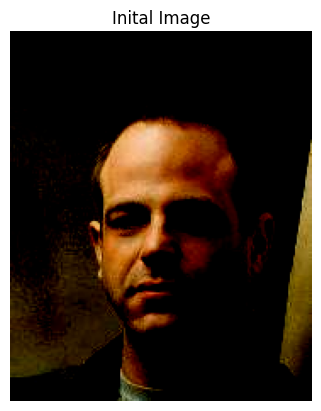

In [5]:
def plot_img(img, title: str):
    img = img.squeeze(0).permute(1, 2, 0)
    import matplotlib.pyplot as plt
    plt.imshow(img)
    plt.axis("off")
    plt.title(title)
    plt.show()

plot_img(x_0, title = "Inital Image")

In [ ]:
import os
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# --------------------------------------------------
# Setup
# --------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ddpm = ddpm.to(device)
ddpm.train()

x_0 = load_test_img().to(device)  # [1, 3, H, W]

optimizer = torch.optim.AdamW(ddpm.parameters(), lr=1e-4)

steps = 8000
save_every = 1000
checkpoint_dir = "./checkpoints"

os.makedirs(checkpoint_dir, exist_ok=True)

best_loss = float("inf")

print(f"Device: {device}")
print(f"Image shape: {x_0.shape}")

# --------------------------------------------------
# Training
# --------------------------------------------------

pbar = tqdm(range(steps), desc="Overfitting single image")

for step in pbar:

    optimizer.zero_grad(set_to_none=True)

    # Forward: sample random timestep and noise
    noise_pred, noise = ddpm(x_0)

    # Epsilon prediction loss
    loss = F.mse_loss(noise_pred, noise)

    # Backward
    loss.backward()

    torch.nn.utils.clip_grad_norm_(ddpm.parameters(), 1.0)

    optimizer.step()

    loss_value = loss.item()

    pbar.set_postfix(loss=f"{loss_value:.5f}", best=f"{best_loss:.5f}")

    # ----------------------------------------------
    # Save best checkpoint
    # ----------------------------------------------

    if loss_value < best_loss:

        best_loss = loss_value

        torch.save({
            "step": step + 1,
            "model_state_dict": ddpm.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss": loss_value,
        }, os.path.join(checkpoint_dir, "best.pt"))

    # ----------------------------------------------
    # Periodic checkpoint
    # ----------------------------------------------

    if (step + 1) % save_every == 0:

        torch.save({
            "step": step + 1,
            "model_state_dict": ddpm.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "loss": loss_value,
        }, os.path.join(checkpoint_dir, f"step_{step + 1}.pt"))

        print(
            f"\nStep {step + 1} | "
            f"Loss: {loss_value:.6f} | "
            f"Noise: mean={noise.mean().item():.3f}, "
            f"std={noise.std().item():.3f} | "
            f"Pred: mean={noise_pred.mean().item():.3f}, "
            f"std={noise_pred.std().item():.3f}"
        )

print(f"\nTraining complete. Best loss: {best_loss:.6f}")

Device: cuda
Image shape: torch.Size([1, 3, 500, 375])


Overfitting single image:   0%|          | 0/4000 [00:00<?, ?it/s]


Step 400 | Loss: 0.012853 | Noise: mean=0.001, std=0.999 | Pred: mean=0.010, std=1.010

Step 800 | Loss: 0.004909 | Noise: mean=0.001, std=0.998 | Pred: mean=0.003, std=0.984

Step 1200 | Loss: 0.024723 | Noise: mean=-0.003, std=1.000 | Pred: mean=-0.004, std=0.991

Step 1600 | Loss: 0.004744 | Noise: mean=-0.001, std=1.001 | Pred: mean=0.012, std=0.986

Step 2000 | Loss: 0.005869 | Noise: mean=0.002, std=1.000 | Pred: mean=-0.001, std=0.998

Step 2400 | Loss: 0.002207 | Noise: mean=0.000, std=0.999 | Pred: mean=0.004, std=0.989

Step 2800 | Loss: 0.001571 | Noise: mean=-0.001, std=0.999 | Pred: mean=-0.002, std=1.001

Step 3200 | Loss: 0.002229 | Noise: mean=0.001, std=1.000 | Pred: mean=-0.004, std=0.978

Step 3600 | Loss: 0.002198 | Noise: mean=-0.003, std=1.000 | Pred: mean=0.010, std=0.998

Step 4000 | Loss: 0.003529 | Noise: mean=-0.002, std=1.001 | Pred: mean=-0.004, std=1.011

Training complete. Best loss: 0.001081


In [5]:
import torch

@torch.no_grad()
def sample(ddpm, config, x_0, device):

    ddpm.eval()

    T = config["T"]

    # Start from Gaussian noise with the same shape as the training image.
    x_t = torch.randn_like(x_0).to(device)

    injector = ddpm.noise_injection_pipieline.noise_injector

    # Move schedules to the sampling device.
    beta = injector.beta.to(device)
    alpha = injector.alpha.to(device)
    alpha_bar = injector.alpha_bar.to(device)

    for t in range(T, 0, -1):

        t_tensor = torch.tensor([t], device=device, dtype=torch.long)

        # Predict noise.
        eps_theta = ddpm.noise_prediction_pipeline(x_t, t_tensor)

        # Extract schedule coefficients.
        beta_t = beta[t]
        alpha_t = alpha[t]
        alpha_bar_t = alpha_bar[t]
        alpha_bar_prev = alpha_bar[t - 1]

        # Posterior variance.
        beta_tilde = (
            beta_t * (1.0 - alpha_bar_prev)
            / (1.0 - alpha_bar_t)
        )

        # Reverse diffusion mean.
        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x_t -
            (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * eps_theta
        )

        # Sample x_(t-1).
        if t > 1:
            z = torch.randn_like(x_t)
            x_t = mean + torch.sqrt(beta_tilde) * z
        else:
            x_t = mean

    return x_t

In [9]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the best checkpoint
checkpoint = torch.load(
    "checkpoints/best.pt",
    map_location=device,
    weights_only=False
)

# Restore model weights
ddpm.load_state_dict(checkpoint["model_state_dict"])
ddpm.to(device)
ddpm.eval()

print(f"Loaded checkpoint from step: {checkpoint.get('step', 'Unknown')}")
print(f"Checkpoint loss: {checkpoint.get('loss', 'Unknown')}")

Loaded checkpoint from step: 3733
Checkpoint loss: 0.0010805237106978893


In [7]:
generated_image = sample(ddpm, config, x_0, device)
generated_image = (generated_image + 1.0) / 2.0 # Convert [-1, 1] -> [0, 1]
generated_image = generated_image.clamp(0, 1)

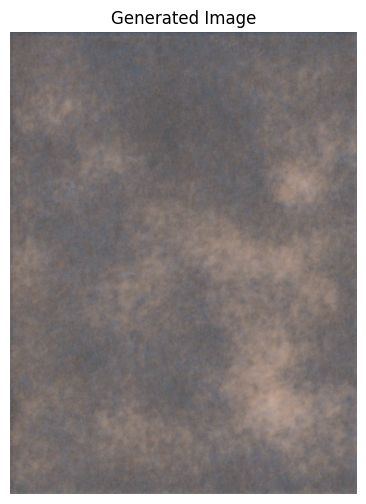

In [8]:
import matplotlib.pyplot as plt

# Convert BCHW -> HWC
image = generated_image[0].permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Generated Image")
plt.show()

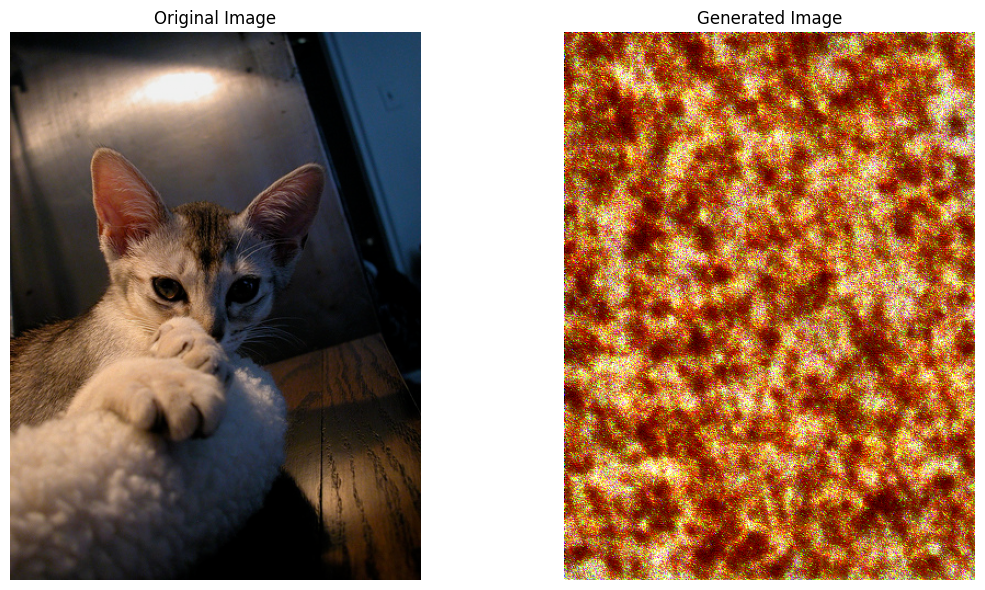

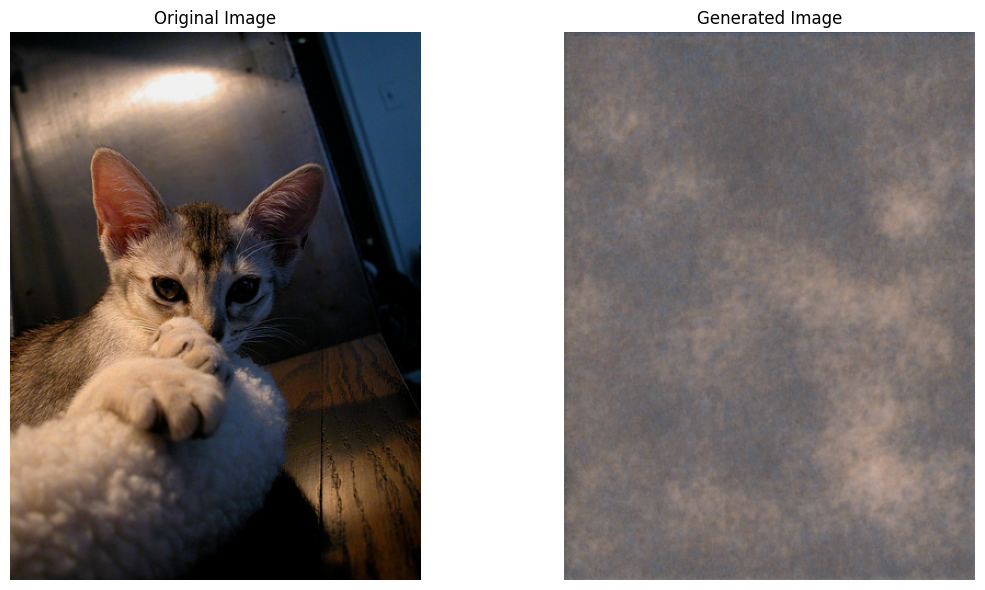

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

original = ((x_0[0] + 1) / 2).clamp(0, 1)
original = original.permute(1, 2, 0).cpu().numpy()

axes[0].imshow(original)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].set_title("Generated Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()